# M3 — Feature selection at a common size (K = 65)
Every selection method is forced to return **exactly K features** (`k_fixed=K` in `src/selection.py`), so methods are compared at equal subset size, then each subset is **retrained** with logistic regression, SVM and LightGBM on the shared 5 folds.

* Training part only (80 %); the test set is never used.
* Per-fold imputation + scaling; search scorer = class-balanced logistic regression.
* K is chosen by the 1-SE rule on the mean CV curve of the ranking methods (ANOVA, MI, chi², L2, RF).

Saved results live in `results/models/m3_fixedk/`; to recompute (about 40 min) run:
```
python scripts/run_m3_fixedk.py choosek | select | classify | summary
```

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import selection as S
from src.evaluate import load_task, train_part
from src.loaders import MODELS_DIR

OUT = MODELS_DIR / "m3_fixedk"
X, y, splits = load_task(); Xtr, ytr = train_part(X, y, splits)
task = S.Task(Xtr, ytr, splits["folds"])
print(Xtr.shape, "| folds:", len(task.folds))

(5232, 131) | folds: 5


## 1. Choosing K
Mean CV macro-F1 of the top-k features over five rankings; K is the smallest size within one standard error of the best mean.

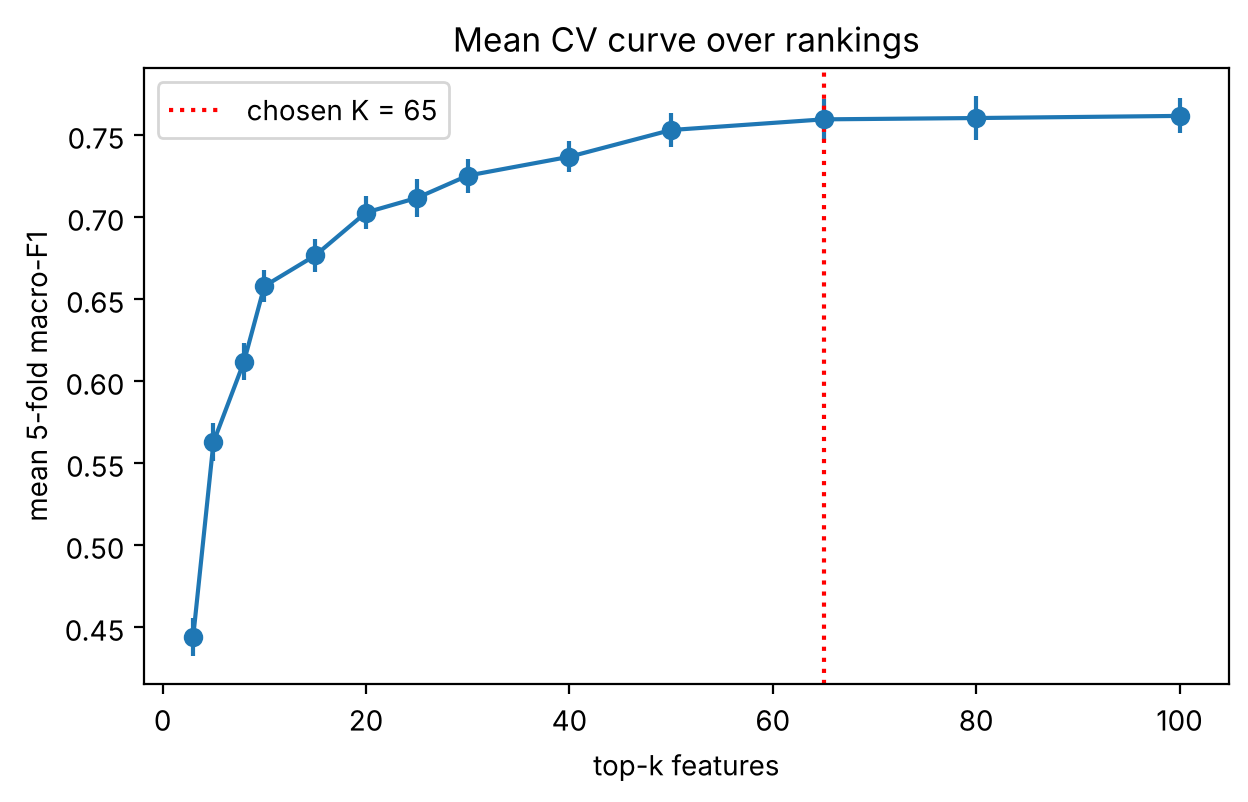

common K = 65 | mean CV curve over ANOVA/MI/chi2/L2/RF rankings; smallest k within 1 SE of the best


In [2]:
ck = json.loads((OUT / "common_k.json").read_text())
K = ck["k"]
cur = pd.DataFrame({"k": ck["k_grid"], "mean_cv_f1": ck["mean_cv_f1"], "mean_cv_std": ck["mean_cv_std"]})
fig, ax = plt.subplots(figsize=(7, 4)); ax.errorbar(cur.k, cur.mean_cv_f1, cur.mean_cv_std, marker="o")
ax.axvline(K, color="r", ls=":", label=f"chosen K = {K}"); ax.set(xlabel="top-k features", ylabel="mean 5-fold macro-F1", title="Mean CV curve over rankings"); ax.legend(); plt.show()
print("common K =", K, "|", ck["rule"])

## 2. How each method returns exactly K features
| Family | Method | How K is enforced |
|---|---|---|
| Filter | variance / correlation | top-K by variance / de-correlated set, then top-K by ANOVA F |
| Filter | ANOVA, MI, chi² | correlation-pruned ranking, top-K |
| Wrapper | SFS / SBS | run to size K with no early stopping (SBS from the pruned set) |
| Wrapper | RFE (LogReg, LightGBM) | recursive elimination to exactly K |
| Embedded | L1, Elastic Net | sparsest C with ≥ K non-zeros, then the K largest \|coef\| (EN: best l1_ratio by CV) |
| Embedded | L2, random forest | rank by \|coef\| / importance, top-K |
| Metaheuristic | GA, PSO, GWO | masks always hold exactly K ones (random-K init, repair after crossover/mutation, stochastic top-K sampling); size penalty off |

In [3]:
subs = {f.stem: json.loads(f.read_text()) for f in sorted((OUT / "subsets").glob("*.json"))}
print({n: s["k"] for n, s in subs.items()})
assert all(s["k"] == K for s in subs.values())

{'embedded_elasticnet': 65, 'embedded_l1': 65, 'embedded_l2': 65, 'embedded_rf': 65, 'filter_anova': 65, 'filter_chi2': 65, 'filter_corr': 65, 'filter_mi': 65, 'filter_variance': 65, 'meta_ga': 65, 'meta_gwo': 65, 'meta_pso': 65, 'wrapper_rfecv_lgbm': 65, 'wrapper_rfecv_logreg': 65, 'wrapper_sbs': 65, 'wrapper_sfs': 65}


## 3. Results: retraining every K-feature subset
CV macro-F1 (5 folds, training part). Search-time scores are optimistic for methods that were tuned with the same logistic regression on the same folds (GA, SFS, SBS, RFE, L2); SVM / LightGBM columns are fairer for them.

In [4]:
summ = pd.read_csv(OUT / "summary.csv")
cv = pd.read_csv(OUT / "subsets_cv.csv")
base = cv[cv.subset == "all_131"].set_index("clf").f1_macro_val_mean
tab = summ[["method", "family", "cv_f1_logreg", "cv_f1_svm", "cv_f1_lgbm", "select_time_s"]].copy()
tab["mean_3_clf"] = tab[["cv_f1_logreg", "cv_f1_svm", "cv_f1_lgbm"]].mean(axis=1)
tab = tab.sort_values("mean_3_clf", ascending=False).reset_index(drop=True)
print("all 131 features:", base.round(4).to_dict())
tab.round(4)

all 131 features: {'logreg': 0.7623, 'svm': 0.7661, 'lgbm': 0.7855}


,method,family,cv_f1_logreg,cv_f1_svm,cv_f1_lgbm,select_time_s,mean_3_clf
0,meta_ga,meta,0.7828,0.7709,0.7804,228.2,0.7780
1,wrapper_rfecv_logreg,wrapper,0.7757,0.7794,0.7762,2.8,0.7771
2,wrapper_sbs,wrapper,0.7790,0.7670,0.7812,302.1,0.7757
3,embedded_l2,embedded,0.7736,0.7726,0.7798,42.4,0.7753
4,meta_gwo,meta,0.7694,0.7714,0.7828,97.7,0.7745
5,wrapper_sfs,wrapper,0.7774,0.7662,0.7781,745.4,0.7739
6,embedded_elasticnet,embedded,0.7631,0.7728,0.7825,223.1,0.7728
7,wrapper_rfecv_lgbm,wrapper,0.7674,0.7727,0.7777,46.7,0.7726
8,embedded_l1,embedded,0.7635,0.7726,0.7808,74.8,0.7723
9,embedded_rf,embedded,0.7628,0.7746,0.7741,5.4,0.7705


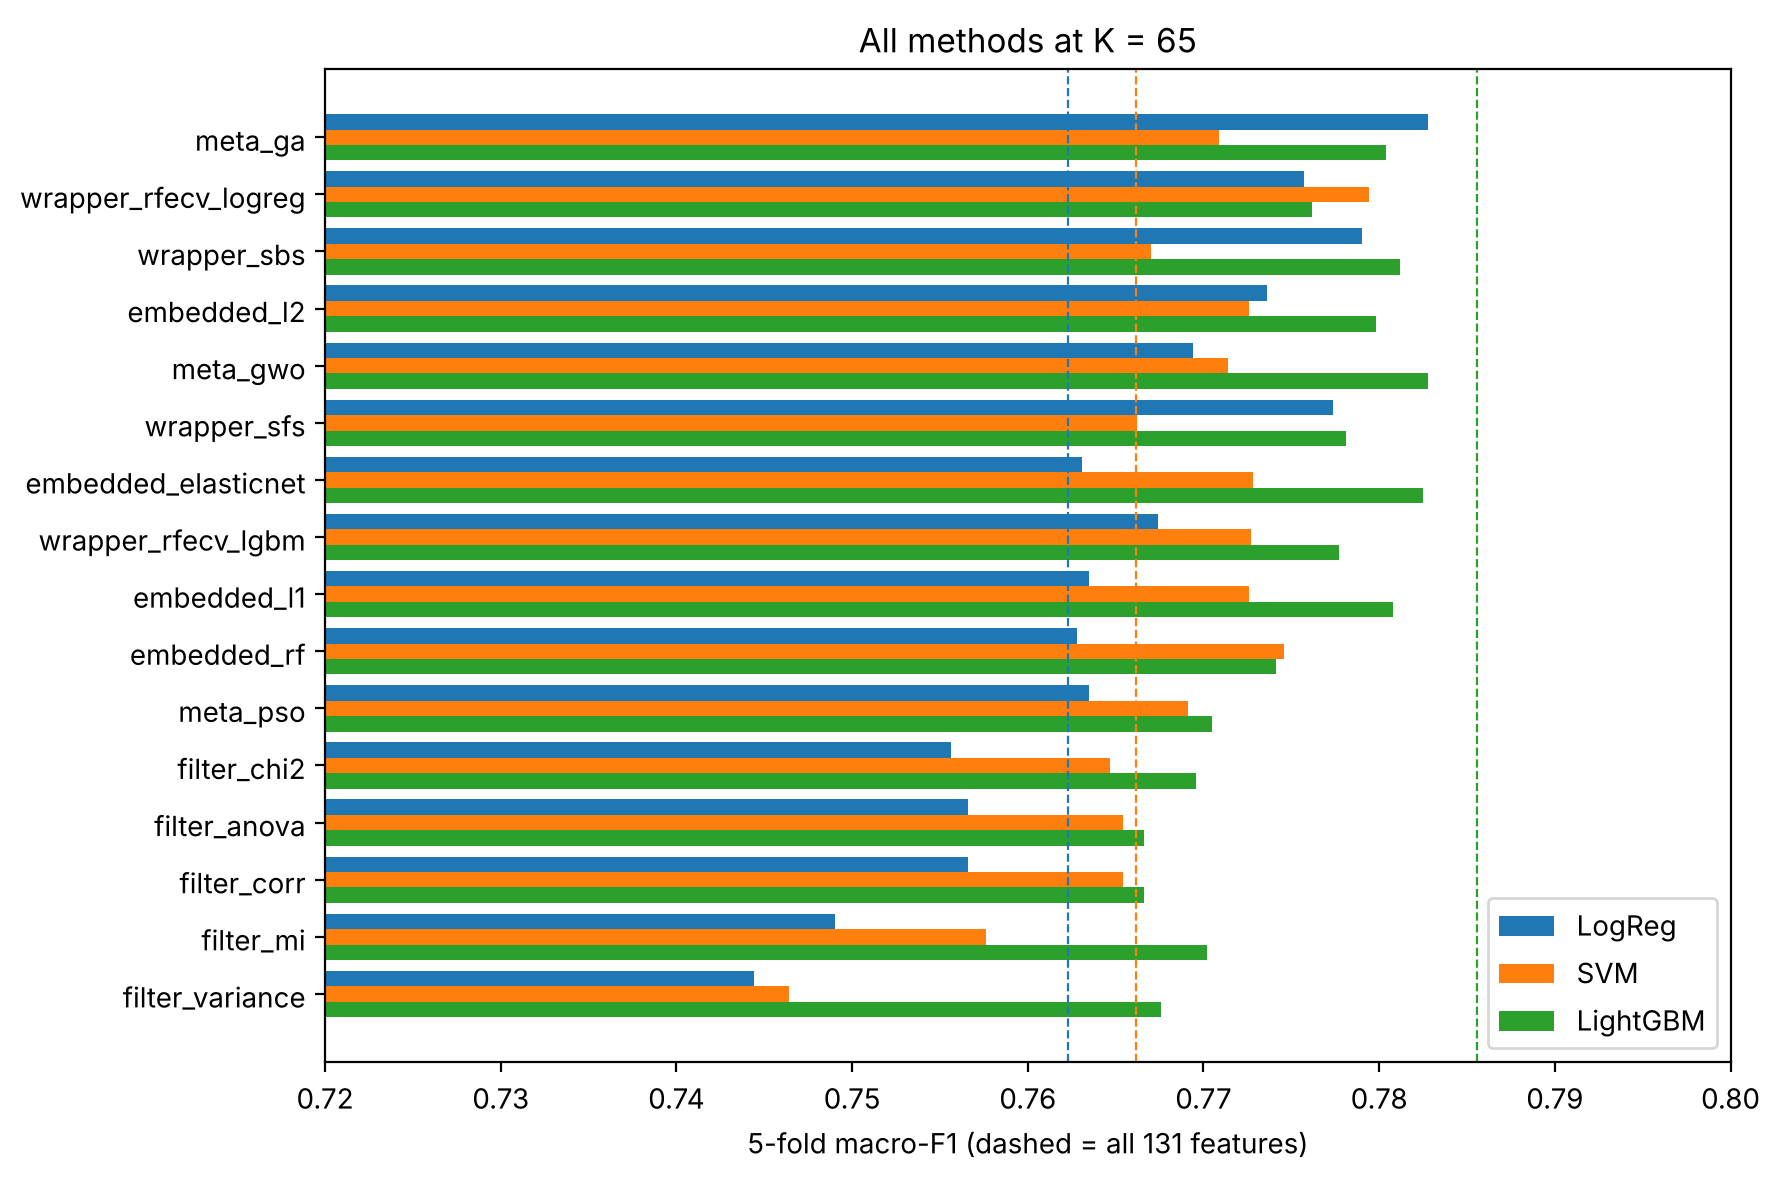

In [5]:
fig, ax = plt.subplots(figsize=(9, 6)); w = 0.27; yy = np.arange(len(tab))
for i, (c, lab) in enumerate([("cv_f1_logreg", "LogReg"), ("cv_f1_svm", "SVM"), ("cv_f1_lgbm", "LightGBM")]):
    ax.barh(yy + (i - 1) * w, tab[c], height=w, label=lab)
    ax.axvline(base[lab.lower() if lab != "LightGBM" else "lgbm"], color=f"C{i}", ls="--", lw=0.8)
ax.set_yticks(yy, tab.method); ax.invert_yaxis(); ax.set_xlim(0.72, 0.80)
ax.set(xlabel="5-fold macro-F1 (dashed = all 131 features)", title=f"All methods at K = {K}"); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

In [6]:
fam = tab.groupby("family")[["cv_f1_logreg", "cv_f1_svm", "cv_f1_lgbm", "mean_3_clf"]].mean().round(4).sort_values("mean_3_clf", ascending=False)
print("Mean by family:"); fam

Mean by family:


,cv_f1_logreg,cv_f1_svm,cv_f1_lgbm,mean_3_clf
family,,,,
wrapper,0.7749,0.7713,0.7783,0.7748
meta,0.7719,0.7705,0.7779,0.7734
embedded,0.7657,0.7732,0.7793,0.7727
filter,0.7524,0.7599,0.7681,0.7602


## 4. Do the methods agree?
Jaccard overlap of the K-feature subsets, and how many methods keep each feature.

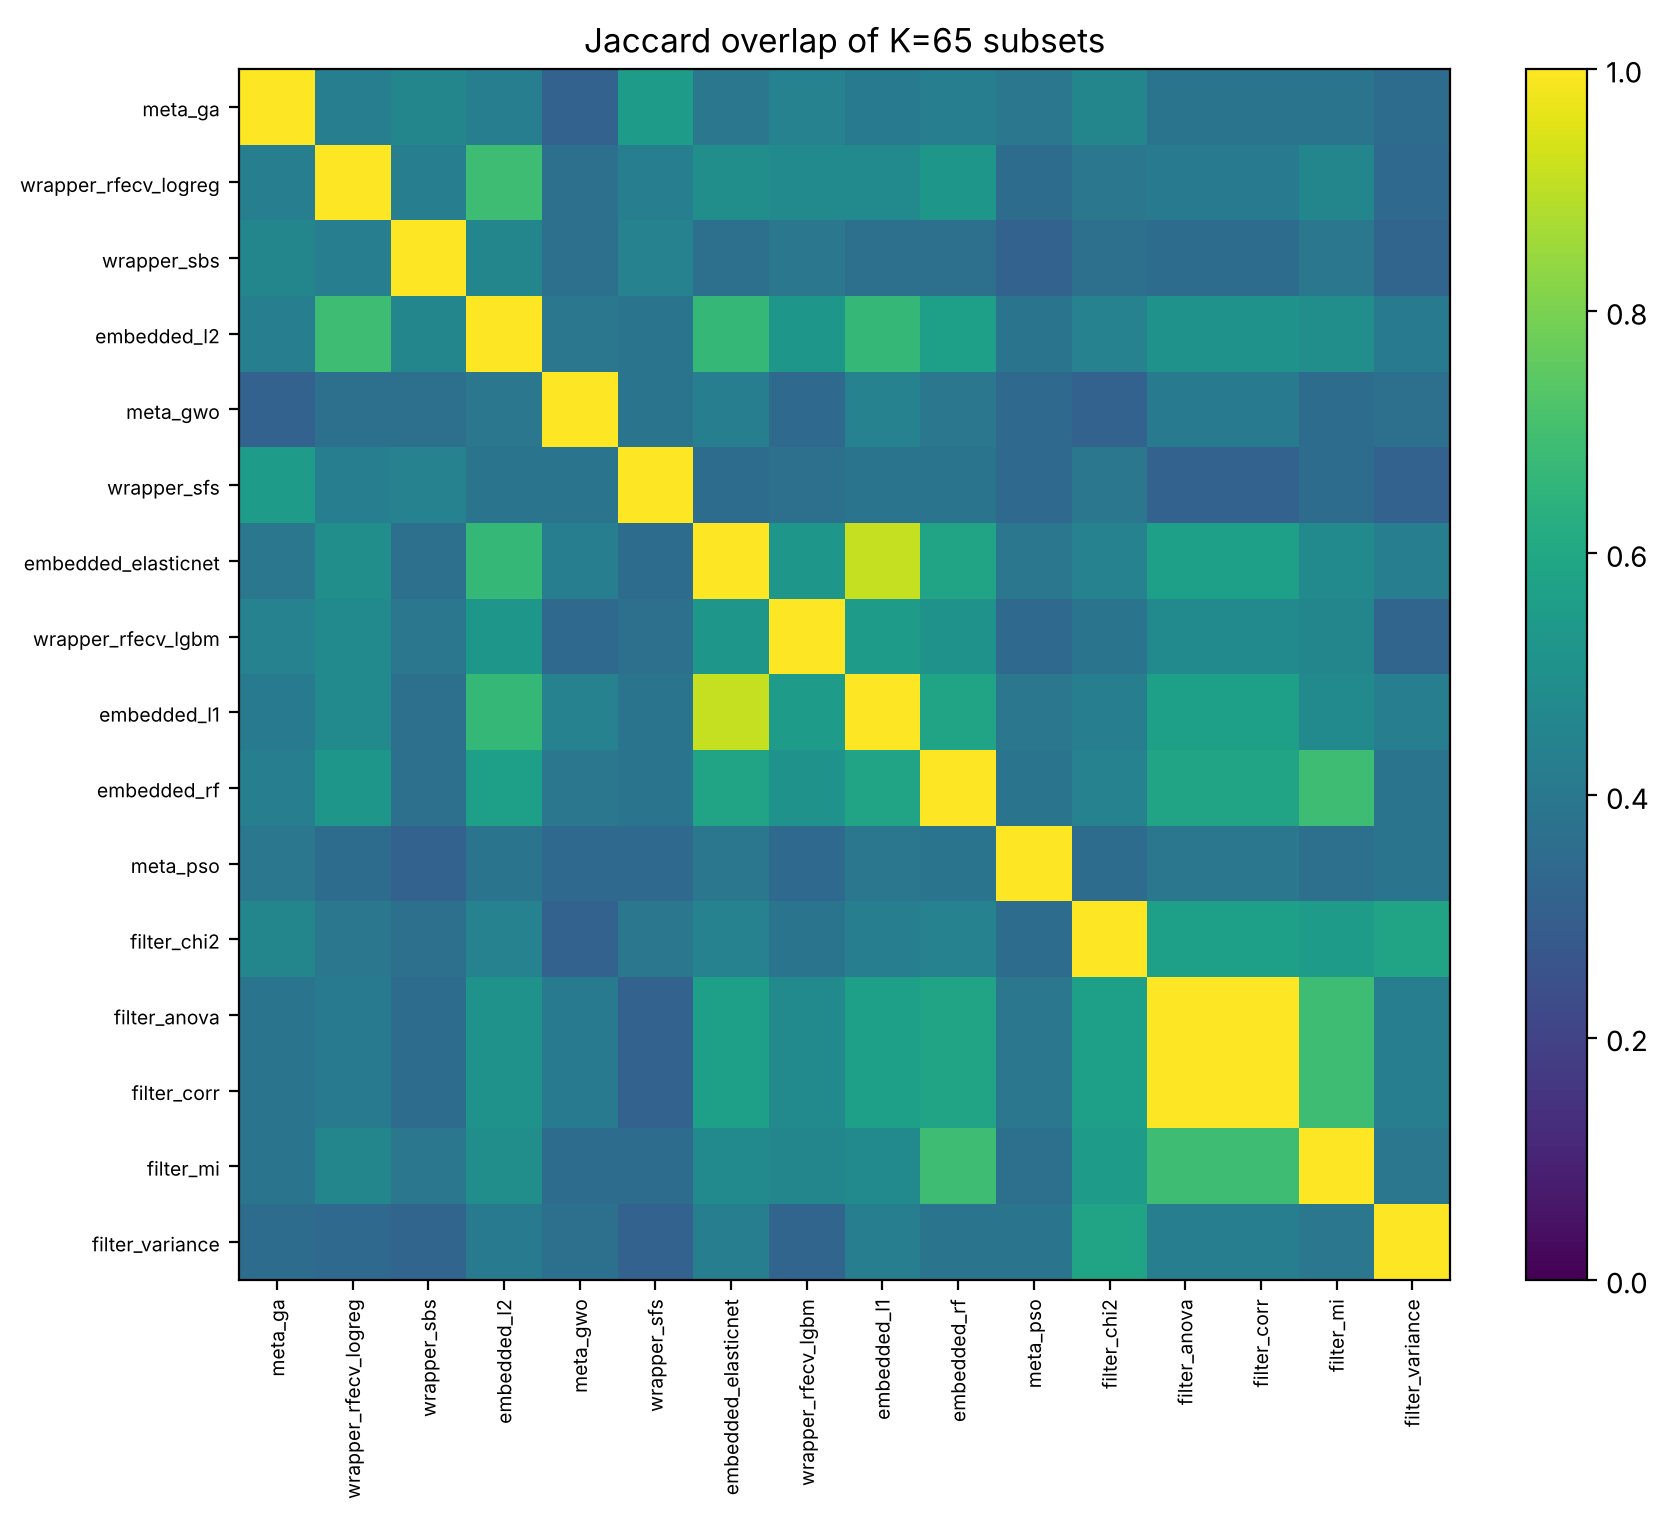

kept by all 16 methods: 7


,methods_keeping
rmssd,16
rr_irregularity,16
pnn50,16
p_duration,16
V1_r_amp,16
age,16
pr_interval,16
V1_s_amp,15
V1_skew,15
qrs_duration,15


In [7]:
names = [n for n in tab.method]
J = pd.DataFrame([[S.jaccard(subs[a]["features"], subs[b]["features"]) for b in names] for a in names], index=names, columns=names)
fig, ax = plt.subplots(figsize=(9, 7.5)); im = ax.imshow(J, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(names)), names, rotation=90, fontsize=7); ax.set_yticks(range(len(names)), names, fontsize=7); plt.colorbar(im); ax.set_title("Jaccard overlap of K=65 subsets"); plt.tight_layout(); plt.show()
votes = pd.Series({f: sum(f in s["features"] for s in subs.values()) for f in X.columns}).sort_values(ascending=False)
print(f"kept by all {len(subs)} methods:", int((votes == len(subs)).sum()))
votes.head(15).to_frame("methods_keeping")

## 5. Take-aways
* **Search methods help logistic regression:** wrappers and metaheuristics (GA, SBS, SFS, RFE-LogReg) give ≈ +0.02 macro-F1 over all 131 features; filters are at or below the baseline; embedded methods and GWO sit in between.
* **LightGBM does not need selection:** no 65-feature subset beats all 131 features (0.786).
* **Differences between top methods are small** (inside fold-to-fold noise of about 0.01–0.02), and the best method depends on the classifier.
* **Caveat:** these are search-time CV scores. Nested CV at K = 65 (`python scripts/run_m3_fixedk.py nested`) was not run and would quantify the selection bias.